In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")

print("Dataset size:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset size:
(891, 12)

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [3]:
# 1. Total passengers in training data
print("Total passengers:", len(df))

# 2. How many survived and how many did not?
print("\nSurvival count:")
print(df["Survived"].value_counts())

# 3. What percentage survived?
print("\nSurvival percentage:")
print(df["Survived"].value_counts(normalize=True) * 100)

Total passengers: 891

Survival count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [4]:
survival_by_gender = df.groupby("Sex")["Survived"].mean() * 100

print(survival_by_gender)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


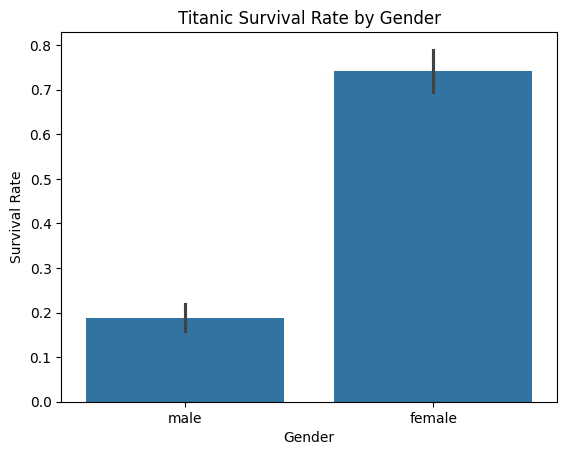

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=df, x="Sex", y="Survived")

plt.title("Titanic Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.show()

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


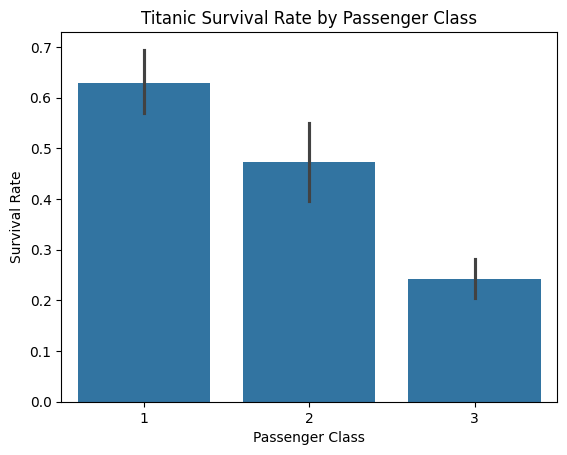

In [6]:
survival_by_class = df.groupby("Pclass")["Survived"].mean() * 100

print(survival_by_class)

sns.barplot(data=df, x="Pclass", y="Survived")
plt.title("Titanic Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

AgeGroup
Child          57.971014
Teenager       42.857143
Young Adult    38.268156
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


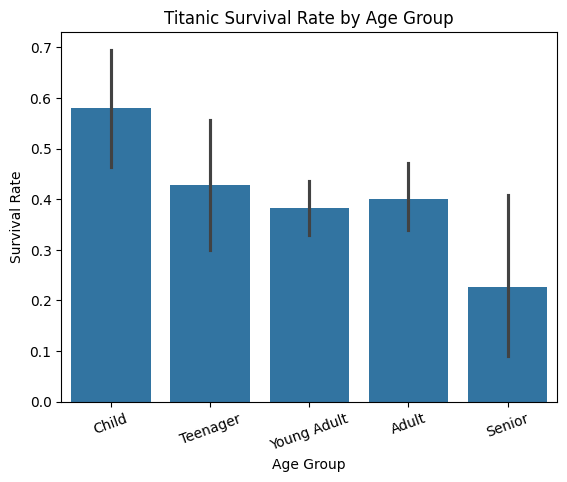

In [7]:
# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

# Calculate survival rate by age group
survival_by_age = df.groupby(
    "AgeGroup", observed=False
)["Survived"].mean() * 100

print(survival_by_age)

# Visualize the results
sns.barplot(data=df, x="AgeGroup", y="Survived")
plt.title("Titanic Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.xticks(rotation=20)
plt.show()

In [8]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

# Missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentage:")
print(missing_percentage.round(2))

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
AgeGroup       177
dtype: int64

Missing value percentage:
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
AgeGroup       19.87
dtype: float64


In [9]:
# Create a copy so the original data stays unchanged
clean_df = df.copy()

# Fill missing Age values with the median
clean_df["Age"] = clean_df["Age"].fillna(
    clean_df["Age"].median()
)

# Fill missing Embarked values with the mode
clean_df["Embarked"] = clean_df["Embarked"].fillna(
    clean_df["Embarked"].mode()[0]
)

# Check missing values again
print("Missing values after cleaning:")
print(clean_df.isnull().sum())

# Check Age statistics
print("\nAge statistics:")
print(clean_df["Age"].describe())

Missing values after cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
AgeGroup       177
dtype: int64

Age statistics:
count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64


In [10]:
import numpy as np
import pandas as pd

# Recreate AgeGroup using the cleaned Age column
clean_df["AgeGroup"] = pd.cut(
    clean_df["Age"],
    bins=[0, 12, 19, 30, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"],
    include_lowest=True
)

# Check missing values again
print("Missing values after updating AgeGroup:")
print(clean_df.isnull().sum())

# Survival rate by gender
print("\nSurvival rate by gender (%):")
print(
    clean_df.groupby("Sex", observed=True)["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

# Survival rate by passenger class
print("\nSurvival rate by passenger class (%):")
print(
    clean_df.groupby("Pclass")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

# Survival rate by age group
print("\nSurvival rate by age group (%):")
print(
    clean_df.groupby("AgeGroup", observed=True)["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

Missing values after updating AgeGroup:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
AgeGroup         0
dtype: int64

Survival rate by gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

Survival rate by age group (%):
AgeGroup
Child          57.97
Teenager       41.05
Young Adult    32.94
Adult          42.05
Senior         22.73
Name: Survived, dtype: float64


# Titanic Data Analysis - Conclusion

## Key Findings
- **Gender:** Female passengers had a higher survival rate (74.20%) than male passengers (18.89%).
- **Passenger Class:** First-class passengers had the highest survival rate (62.96%), while third-class passengers had the lowest (24.24%).
- **Age Group:** Children had the highest survival rate (57.97%), while senior passengers had the lowest (22.73%).
- **Data Cleaning:** Missing values in the Age column were handled, and age groups were created for further analysis.

## Skills Demonstrated
Python, Pandas, NumPy, Data Cleaning, Exploratory Data Analysis (EDA), Data Visualization, and Statistical Analysis.

## Conclusion
The analysis indicates that survival rates differed by gender, passenger class, and age group. The project demonstrates how Python-based data analysis can uncover patterns and insights from real-world datasets.